<a href="https://colab.research.google.com/github/giovanardo/Project2/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2: Regression Trees and Random Forests

**Goal: Use a real dataset to predict a numerical outcome. Build one decision tree regressor and one
random forest regressor, compare their performance, investigate two random forest settings, and
explain feature importance.**

## Part 1 | Introducing the dataset

This project uses data from Equity in Athletics Data Analysis database, maintained by the Office of Postsecondary Education of the U.S. Department of Education.

The dataset contains information about athletics data for 2024. The predictors describe the size and profile of each athletics program: the institution’s athletic classification and sector (public four-year or private nonprofit), the number of male and female undergraduates, the number of women and men participating in athletics, the number of head and assistant coaches, and participation in selected sports such as women’s basketball, soccer, volleyball.

The target is to predict the total expenses of an institution’s women’s athletic teams.

[Dataset Link](https://ope.ed.gov/athletics/#/$0)

In [49]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor

DATA_PATH = '/content/drive/MyDrive/data 201/Projects/datasets/EADA_2024.xlsx'
athletics = pd.read_excel(DATA_PATH)

print(athletics.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(2040, 4275)


There is 2040 institutions and 4275 variables in the original dataset.

First step is to select my interest variables to work with a small dataframe

| Variable | Type | Meaning |
|------------------------|------------------------|------------------------|
| IL_EXP_WOMEN (target) | Numerical | Total expenses of an institution’s women’s athletic teams |
| PARTIC_WOMEN_Bskball | Numerical | women participation in basketball |
| PARTIC_WOMEN_Soccer | Numerical | women participation in soccer |
| PARTIC_WOMEN_Vollball | Numerical | women participation in volleyball |
| EFFemaleCount | Numerical | the number of female undergraduates |
| EFMaleCount | Numerical | the number of male undergraduates |
| IL_SUM_PARTIC_MEN | Numerical | the number of men participating in athletics |
| IL_SUM_PARTIC_WOMEN | Numerical | the number of women participating in athletics |
| IL_WOMEN_TOTAL_HDCOACH | Numerical | the number of head coaches |
| IL_WOMEN_TOTAL_ASTCOACH | Numerical | the number of assistant coaches |
| IL_MEN_TOTAL_HEADCOACH | Numerical | the number of men's head coaches |
| IL_MEN_TOTAL_ASSTCOACH | Numerical | the number of men's assistant coaches |
| classification_name | Categorical | the institution’s athletic classification (NCAA, NCJAA) |
| sector_name | Categorical | sector (public two-year or four-year, private and nonprofit) |
| institution_name | Categorical | the name of the institution |

In [20]:
y_col = "IL_EXP_WOMEN"
sport_cols = ["PARTIC_WOMEN_Bskball", "PARTIC_WOMEN_Soccer", "PARTIC_WOMEN_Vollball"]
num_cols = ["EFFemaleCount", "EFMaleCount",
            "IL_SUM_PARTIC_WOMEN", "IL_SUM_PARTIC_MEN",
            "IL_WOMEN_TOTAL_HDCOACH", "IL_WOMEN_TOTAL_ASTCOACH",
            "IL_MEN_TOTAL_HEADCOACH", "IL_MEN_TOTAL_ASSTCOACH"]
cat_cols = ["classification_name", "sector_name"]
#creating a new df from the original file to select the variables i will use

clean = ["institution_name", y_col] + cat_cols + num_cols + sport_cols
df = athletics[clean].copy() #storing the df

#transforming target in millions of dollars
df[y_col] = df[y_col] / 1_000_000

print("Shape:", df.shape)

Shape: (2040, 15)


In [21]:
df.head()

,institution_name,IL_EXP_WOMEN,classification_name,sector_name,EFFemaleCount,EFMaleCount,IL_SUM_PARTIC_WOMEN,IL_SUM_PARTIC_MEN,IL_WOMEN_TOTAL_HDCOACH,IL_WOMEN_TOTAL_ASTCOACH,IL_MEN_TOTAL_HEADCOACH,IL_MEN_TOTAL_ASSTCOACH,PARTIC_WOMEN_Bskball,PARTIC_WOMEN_Soccer,PARTIC_WOMEN_Vollball
0,Alabama A & M University,2.451537,NCAA Division I-FCS,"Public, 4-year or above",3077,2142,197,287,7.0,11.0,6.0,23.0,16.0,39.0,24.0
1,University of Alabama at Birmingham,6.293790,NCAA Division I-FBS,"Public, 4-year or above",6184,3621,250,224,9.0,16.0,6.0,22.0,15.0,33.0,17.0
2,University of Alabama in Huntsville,2.533025,NCAA Division II without football,"Public, 4-year or above",2170,3472,210,313,6.0,7.0,5.0,6.0,23.0,28.0,19.0
3,Alabama State University,2.753360,NCAA Division I-FCS,"Public, 4-year or above",1883,1076,181,251,8.0,17.0,6.0,21.0,18.0,24.0,20.0
4,The University of Alabama,24.204112,NCAA Division I-FBS,"Public, 4-year or above",16827,13129,410,394,10.0,33.0,7.0,29.0,30.0,29.0,20.0


### Cleaning the data

- The categorical variables had institutions that were removed for the prediction because it had some classes with small observations (Independent and Sector Unknown)
- Women institutions with expend = 0 were removed
-  Sports with no team were filled with 0
- Missing values from coaches were removed

In [22]:
df['classification_name'].value_counts()

,count
classification_name,
NCAA Division III with football,235
NJCAA Division I,211
NCAA Division III without football,172
NAIA Division I,158
NCAA Division II with football,156
NJCAA Division II,152
NCAA Division II without football,136
NCAA Division I-FBS,129
NCAA Division I-FCS,129


In [23]:
#removing Independent from classification
df = df[df['classification_name'] != 'Independent']

In [24]:
df['sector_name'].value_counts()

,count
sector_name,
"Private nonprofit, 4-year or above",834
"Public, 4-year or above",589
"Public, 2-year",575
"Private for-profit, 4-year or above",22
"Private nonprofit, 2-year",12
Sector Unknown,1


In [25]:
#removing Unknown from sector
df = df[df['sector_name'] != 'Sector Unknown']

In [26]:
df.shape

(2032, 15)

In [27]:
# Which columns have missing values?
print(df.isna().sum())

institution_name             0
IL_EXP_WOMEN                24
classification_name          0
sector_name                  0
EFFemaleCount                0
EFMaleCount                  0
IL_SUM_PARTIC_WOMEN          0
IL_SUM_PARTIC_MEN            0
IL_WOMEN_TOTAL_HDCOACH      26
IL_WOMEN_TOTAL_ASTCOACH     73
IL_MEN_TOTAL_HEADCOACH      17
IL_MEN_TOTAL_ASSTCOACH      58
PARTIC_WOMEN_Bskball       188
PARTIC_WOMEN_Soccer        442
PARTIC_WOMEN_Vollball      272
dtype: int64


In [28]:
#keep institutions with women's team expenses > 0
df = df.dropna(subset=[y_col])
df = df[df[y_col] > 0]

In [29]:
#blank in the sport columns means no team = 0
df[sport_cols] = df[sport_cols].fillna(0)

In [30]:
#now drop the few rows still missing coach counts
n_before = len(df)
df = df.dropna()
print("Rows removed (coach counts):", n_before - len(df), "| Rows left:", len(df))

Rows removed (coach counts): 62 | Rows left: 1920


In [31]:
# One-hot encode the two text columns using pd
X = pd.get_dummies(df.drop(columns=['IL_EXP_WOMEN', 'institution_name']), columns=['classification_name', 'sector_name']).astype(int)
y = df['IL_EXP_WOMEN']

## Part 2 | Prepare data and fit a single tree

Separate the predictors (X) and target (y). Split the data into 70% training and 30% testing, using
random_state=50. Apply any preprocessing appropriately; do not use the test set to learn
preprocessing steps.

In [32]:
# Hold out 30% of institutions for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=50)


print(X_train.shape, X_test.shape) #see the proportion

#check train set
X_train.head()

(1344, 34) (576, 34)


,EFFemaleCount,EFMaleCount,IL_SUM_PARTIC_WOMEN,IL_SUM_PARTIC_MEN,IL_WOMEN_TOTAL_HDCOACH,IL_WOMEN_TOTAL_ASTCOACH,IL_MEN_TOTAL_HEADCOACH,IL_MEN_TOTAL_ASSTCOACH,PARTIC_WOMEN_Bskball,PARTIC_WOMEN_Soccer,...,classification_name_NJCAA Division II,classification_name_NJCAA Division III,classification_name_NWAC,classification_name_Other,classification_name_USCAA,"sector_name_Private for-profit, 4-year or above","sector_name_Private nonprofit, 2-year","sector_name_Private nonprofit, 4-year or above","sector_name_Public, 2-year","sector_name_Public, 4-year or above"
1237,231,220,22,18,2,2,1,2,8,0,...,0,0,0,0,1,0,0,1,0,0
650,732,487,149,201,9,17,9,22,17,30,...,0,0,0,0,0,0,0,1,0,0
164,933,765,40,135,4,5,4,16,8,15,...,0,0,0,0,0,0,0,0,1,0
1664,477,287,203,215,9,8,8,9,13,50,...,0,0,0,0,0,0,0,1,0,0
961,837,697,72,72,5,8,4,9,14,18,...,0,0,0,0,0,0,0,0,1,0


Fit a DecisionTreeRegressor with max_depth=None and random_state=50. Report training and
test RMSE. Explain whether the results suggest overfitting.

In [33]:
tree = DecisionTreeRegressor(max_depth=None, random_state=50)
tree.fit(X_train, y_train) #fit to train

train_rmse = np.sqrt(mean_squared_error(y_train, tree.predict(X_train)))
test_rmse  = np.sqrt(mean_squared_error(y_test,  tree.predict(X_test)))

print('Train RMSE', round(train_rmse, 3))
print('Test RMSE', round(test_rmse, 3))

Train RMSE 0.0
Test RMSE 2.023


### The results
> If train RMSE = 0.0 it means that with none `max_depth` the three keeps dividing itself until memorizes the train set, there are no errors.

> Test RMSE 2.023: Institutions the model never saw have its error about 2.023 millions.

> The gap between the two RMSE indicate overfitting.

## Part 3 | Build and compare a random forest

Fit a RandomForestRegressor with n_estimators=100, random_state=50, and n_jobs=-1. Use the
same training and test split as the single tree.

In [48]:
forest = RandomForestRegressor(n_estimators=100,
                                random_state=50,
                                n_jobs = -1)
forest.fit(X_train, y_train)

print("Forest, R on training set:", round(forest.score(X_train, y_train), 3))
print("Forest, R on test set:    ", round(forest.score(X_test, y_test), 3))

Forest, R on training set: 0.987
Forest, R on test set:     0.88


Report training and test RMSE for both models in one small table. Which model predicts unseen
values more accurately? Explain using your results.

In [41]:
train_rmse1 = np.sqrt(mean_squared_error(y_train, forest.predict(X_train)))
test_rmse1  = np.sqrt(mean_squared_error(y_test,  forest.predict(X_test)))

results = pd.DataFrame({
    'Model': ['Decision tree', 'Random forest (100 trees)'],
    'Train RMSE': [round(train_rmse, 3),  round(train_rmse1, 3)],
    'Test RMSE':  [round(test_rmse, 3),   round(test_rmse1, 3)]
})
results

,Model,Train RMSE,Test RMSE
0,Decision tree,0.000,2.023
1,Random forest (100 trees),0.479,1.484


### The results

> Random forest has a better prediction for unseen institutions compared to the Decision Tree. Adding `n_estimator` = 100 gives better results because more tree reduces variance and randomize them to get the avarage. The Test RMSE now is 1.484 millions, a significant reduction when compared to the Tree Test RMSE of 2.023.

> The model for decision tree memorized the training set, which was an indicator to overfitting. The forest has its error much lower.

## Part 4 | Investigate two random forest parameters

Keep all other settings fixed while investigating each parameter. Use 5-fold cross-validation on the
training data and compare mean cross-validation RMSE (lower is better). Do not use the test set to
select parameter values.

Number of trees (n_estimators): Compare 10, 50, and 100 trees, with max_depth=None. Make a
line graph showing n_estimators versus mean cross-validation RMSE. What happens as you add
trees?

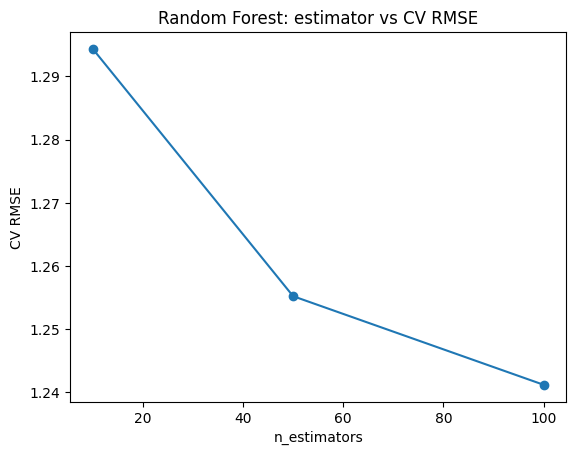

In [42]:
estimators = [10,50,100]
cv_rmse = []
for e in estimators:
    m = RandomForestRegressor(n_estimators = e,
                              max_depth = None,
                              random_state=50,
                              n_jobs=-1)
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())


plt.plot(estimators, cv_rmse, marker='o')
plt.xlabel('n_estimators'); plt.ylabel('CV RMSE');plt.title('Random Forest: estimator vs CV RMSE'); plt.show()

> The more trees we add, the lower RMSE tends to be.

Tree depth (max_depth): Compare 2, 4, 8, and 12, with n_estimators=100. Make a line graph
showing max_depth versus mean cross-validation RMSE. How does limiting depth affect
performance?

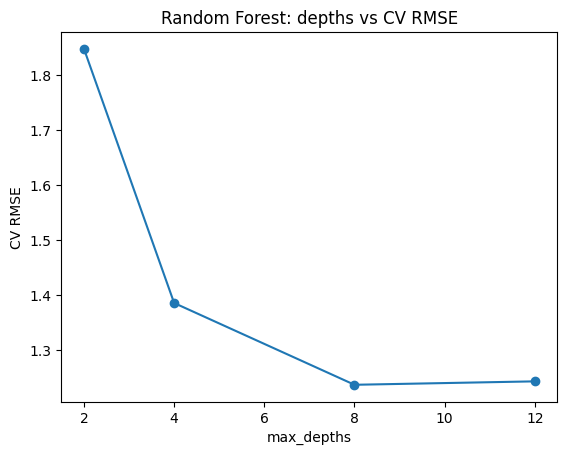

In [37]:
depths = [2, 4, 8, 12]
cv_rmse_d = []

for d in depths:
  m1 = RandomForestRegressor(n_estimators= 100,
                             max_depth = d,
                             random_state=50,
                             n_jobs=-1)
  scores = cross_val_score(m1, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
  cv_rmse_d.append(-scores.mean())


plt.plot(depths, cv_rmse_d, marker='o')
plt.xlabel('max_depths'); plt.ylabel('CV RMSE'); plt.title('Random Forest: depths vs CV RMSE'); plt.show()


> The more limitation in depths, the greater the error is. Until it reaches a point where the error starts to grow again, in this case depth = 8.

Choose a final combination using the cross-validation results. Fit that forest on all the training
data, and report its test RMSE. Briefly compare it with your original tree and forest.

In [38]:
best_estimator = list(estimators)[int(np.argmin(cv_rmse))]
best_depth = list(depths)[int(np.argmin(cv_rmse_d))]
best_forest = RandomForestRegressor(n_estimators=best_estimator,
                                    max_depth=best_depth,
                                    random_state=50).fit(X_train, y_train)

def rmse(model): return np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
print('Best n_estimators:', best_estimator, '| Best max_depth:', best_depth)
print('Test RMSE:', round(rmse(best_forest), 3))

Best n_estimators: 100 | Best max_depth: 8
Test RMSE: 1.477


### Comparing models:

*   When maximazing estimators, for example `n_estimator = 100` the errors tend to decrease. The orginal forest set the hiper parameter to 100, while the CV showed the same result ranked as best when comparing to 10 and 50.
*   When setting the depths and limiting the `max_depths = 2, 4, 8, 12` it minimizes the error without ouverfitting. The original tree has no limitation which results in memorizing the train set (overfit). That makes sense if we look at the graph and notice that after depth 8, the error starts to increase.



## Part 5 | Feature importance and conclusion

Create a labeled bar chart of the 10 most important predictors in your final random forest (or all
predictors if fewer than 10).

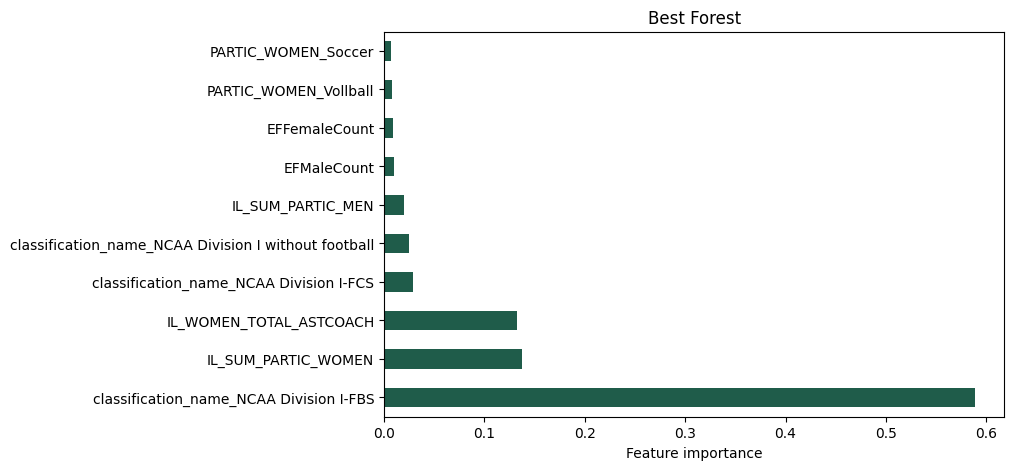

In [47]:
imp = pd.Series(best_forest.feature_importances_, index=X.columns).sort_values(ascending = False)
most = imp.head(10)

most.plot(kind='barh', figsize=(8, 5), color='#1F5C4A')
plt.xlabel('Feature importance'); plt.title('Best Forest'); plt.show()

Identify the three most important predictors. Explain in plain language what these features
represent and why they might be useful for prediction. Remember: feature importance does not
prove causation.

> The three most important predictors are: `classification_name_NCAA Division I-FBS`, `IL_SUM_PARTIC_WOMEN` and `IL_WOMEN_TOTAL_ASTCOACH`

> NCAA Division I-FBS indicates that the institution competes in the top level of college football. These schools tend to have the largest athletics budgets.

> IL_SUM_PARTIC_WOMEN is the total number of women participating in athletics. More athletes means more teams, equipment, travel and scholarships, so higher expenses.

> IL_WOMEN_TOTAL_ASTCOACH is the number of assistant coaches for women's teams. Coaching staff is a major cost, and a larger staff reflects a larger program.

> Feature importance has no direction (it does not say whether they cause higher spending).

Write a short conclusion (4–6 sentences): What did you predict, which model worked best, what
did the two parameters teach you, and what is one limitation of your analysis?

> The predicton uses data from 2024 Equity in Athletics (EADA) survey and the target is to predict the total expenses of women's athletic teams at U.S institutions. The random forest had the best output, with test RMSE of 1.484 million compared with 2.023 million for the decision tree. Cross-validation showed that adding number of estimators reduced the train error and the best depth = 8. The final forest (100 trees and 8 depths) had the best Test RMSE of 1.477 millions. One limitation is that the for this prediction I choose only few sports and no others variables, such as revenue, so different groups might explain better the expending.